In [1]:
import numpy as np, matplotlib.pyplot as plt, pandas as pd, tensorflow as tf
from pathlib import Path

DATA_FILE = Path('data') / 'data.csv'

I0000 00:00:1791146220.667785    8327 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791146220.673588    8327 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791146221.263889    8327 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791146222.756763    8327 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

# Data analysis

In [2]:
df = pd.read_csv(DATA_FILE, index_col=0, parse_dates=True)
df.head()

,OilRateWellTeststb/d,LiquidRateWellTeststb/d,WellTestBSW*100%,DailyBHPpsia,DailyTHPpsia,WellTestChoke64ths,IntraDayChoke64ths,GORWellTestscf/stb,WellTestTGLRscf/stb,DailyBHTDeg.F,...,DailyOilRatestb/d BA-07,DailyWaterRatestb/d BA-07,DailyGasRateMMscf/d BA-07,DailyLiftGasRateMMscf/d BA-07,DailyWaterInjectionUptimehours EA-14,DailyWaterInjectionRatestb/d EA-14,DailyBHPpsia EA-14,DailyTHPpsia EA-14,DailyBHTDegF EA-14,DailyWaterInjectionRatestb/d_factor EA-14
Date,,,,,,,,,,,,,,,,,,,,,
1970-01-01,0.0,0,0,1074.11,330.15,0,0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1970-01-02,0.0,0,0,0.00,0.00,0,0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1970-01-03,0.0,0,0,0.00,0.00,0,0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1970-01-04,0.0,0,0,0.00,0.00,0,0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1970-01-05,0.0,0,0,0.00,0.00,0,0,0.0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [15]:
dtypes_df = df.dtypes.reset_index()
dtypes_df.columns = ["column", "dtype"]
dtypes_df["dtype"] = dtypes_df["dtype"].astype(str)
print(dtypes_df.to_string(index=False))

                                   column   dtype
                     OilRateWellTeststb/d float64
                  LiquidRateWellTeststb/d   int64
                         WellTestBSW*100%   int64
                             DailyBHPpsia float64
                             DailyTHPpsia float64
                       WellTestChoke64ths   int64
                       IntraDayChoke64ths   int64
                       GORWellTestscf/stb float64
                      WellTestTGLRscf/stb   int64
                            DailyBHTDeg.F float64
                WellTestLiftGasRateMscf/d float64
                          WellTestBHPpsia float64
                       DailyBHPpsia BA-07 float64
                       DailyTHPpsia BA-07 float64
                       DailyBHTDegF BA-07 float64
         DailyProductionUptimehours BA-07 float64
                  DailyOilRatestb/d BA-07 float64
                DailyWaterRatestb/d BA-07 float64
                DailyGasRateMMscf/d BA-07 float64


In [4]:
len(df)

18363

In [4]:
df.isna().any()

OilRateWellTeststb/d                         False
LiquidRateWellTeststb/d                      False
WellTestBSW*100%                             False
DailyBHPpsia                                 False
DailyTHPpsia                                 False
WellTestChoke64ths                           False
IntraDayChoke64ths                           False
GORWellTestscf/stb                           False
WellTestTGLRscf/stb                          False
DailyBHTDeg.F                                False
WellTestLiftGasRateMscf/d                    False
WellTestBHPpsia                              False
DailyBHPpsia BA-07                           False
DailyTHPpsia BA-07                           False
DailyBHTDegF BA-07                           False
DailyProductionUptimehours BA-07             False
DailyOilRatestb/d BA-07                      False
DailyWaterRatestb/d BA-07                    False
DailyGasRateMMscf/d BA-07                    False
DailyLiftGasRateMMscf/d BA-07  

In [5]:
df.describe()

,OilRateWellTeststb/d,LiquidRateWellTeststb/d,WellTestBSW*100%,DailyBHPpsia,DailyTHPpsia,WellTestChoke64ths,IntraDayChoke64ths,GORWellTestscf/stb,WellTestTGLRscf/stb,DailyBHTDeg.F,...,DailyOilRatestb/d BA-07,DailyWaterRatestb/d BA-07,DailyGasRateMMscf/d BA-07,DailyLiftGasRateMMscf/d BA-07,DailyWaterInjectionUptimehours EA-14,DailyWaterInjectionRatestb/d EA-14,DailyBHPpsia EA-14,DailyTHPpsia EA-14,DailyBHTDegF EA-14,DailyWaterInjectionRatestb/d_factor EA-14
count,18363.000000,18363.000000,18363.000000,18363.000000,18363.000000,18363.000000,18363.000000,18363.000000,18363.000000,18363.000000,...,18363.000000,18363.000000,18363.000000,18363.000000,18363.000000,18363.000000,18363.000000,18363.000000,18363.000000,18363.000000
mean,18.271258,24.725862,40.543484,310.818032,96.808215,2.219681,27.131188,58.298490,43.250667,40.752479,...,179.260740,78.487589,0.106519,0.064222,5.251435,1341.754849,210.215677,126.794672,0.324375,67.087742
std,253.561278,309.800518,430.532961,3123.551408,197.860744,20.863253,68.246620,6696.919551,3829.279899,62.245994,...,662.272412,243.342560,0.504221,0.349040,9.739669,2862.158611,623.330615,295.451449,6.593617,143.107931
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,-0.010000,0.000000,0.000000,0.000000,0.000000,-39.680000,-0.040000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,552.010000,87.220000,0.000000,0.000000,0.000000,0.000000,134.670000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.700000,0.000000,0.000000
max,8823.190000,11045.000000,22510.000000,419508.140000,2828.780000,200.000000,200.000000,906446.380000,517846.000000,287.700000,...,8509.960000,2472.950000,10.230000,3.050000,24.000000,29379.190000,2410.330000,13010.280000,135.000000,1468.959500


In [6]:
# 1. Percentages / bounded quantities
df.loc[df["WellTestBSW*100%"] > 100, "WellTestBSW*100%"] = np.nan   # also < 0

# 2. Uptime hours must be 0-24
for c in ["DailyProductionUptimehours BA-07", "DailyWaterInjectionUptimehours EA-14"]:
    df.loc[~df[c].between(0, 24), c] = np.nan

# 3. Tiny negatives (gas rate -0.01, BHT -0.04) are sensor noise
for c in df.columns:
    if any(k in c for k in ["Rate", "Choke", "Uptime", "Deg"]):
        df[c] = df[c].clip(lower=0)

# 4. Well-test ratios blow up when oil rate is tiny (GOR max 906,446, TGLR 517,846)
for c in ["GORWellTestscf/stb", "WellTestTGLRscf/stb"]:
    hi = df[c].quantile(0.99)          # ideally computed on train only
    df.loc[df[c] > hi, c] = np.nan

# 5. Consistency checks
bad = (df["DailyProductionUptimehours BA-07"] == 0) & (df["DailyOilRatestb/d BA-07"] > 0)
print("oil produced with 0 uptime:", bad.sum())

# 6.  Pressure cannot be very low
working_time_col = 'DailyProductionUptimehours BA-07'
for col in ['DailyBHPpsia EA-14', 'DailyTHPpsia EA-14']:
    df.loc[(df[col] < 0) & (df[working_time_col] <= 0), col] = 0
    df.loc[(df[col] < 0) & ~(df[working_time_col] <= 0), col] = np.nan

df.describe()

oil produced with 0 uptime: 0


,OilRateWellTeststb/d,LiquidRateWellTeststb/d,WellTestBSW*100%,DailyBHPpsia,DailyTHPpsia,WellTestChoke64ths,IntraDayChoke64ths,GORWellTestscf/stb,WellTestTGLRscf/stb,DailyBHTDeg.F,...,DailyOilRatestb/d BA-07,DailyWaterRatestb/d BA-07,DailyGasRateMMscf/d BA-07,DailyLiftGasRateMMscf/d BA-07,DailyWaterInjectionUptimehours EA-14,DailyWaterInjectionRatestb/d EA-14,DailyBHPpsia EA-14,DailyTHPpsia EA-14,DailyBHTDegF EA-14,DailyWaterInjectionRatestb/d_factor EA-14
count,18363.000000,18363.000000,18157.0,18363.000000,18363.000000,18363.000000,18363.000000,18221.0,18180.000000,18363.000000,...,18363.000000,18363.000000,18363.00000,18363.000000,18363.000000,18363.000000,18363.000000,18359.000000,18363.000000,18363.000000
mean,18.271258,24.725862,0.0,310.818032,96.808215,2.219681,27.131188,0.0,0.339439,40.752479,...,179.260740,78.487589,0.10652,0.064222,5.251435,1341.754849,210.215677,126.967138,0.328365,67.087742
std,253.561278,309.800518,0.0,3123.551408,197.860744,20.863253,68.246620,0.0,10.401078,62.245994,...,662.272412,243.342560,0.50422,0.349040,9.739669,2862.158611,623.330615,295.408651,6.593408,143.107931
min,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.0,552.010000,87.220000,0.000000,0.000000,0.0,0.000000,134.670000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,14.700000,0.000000,0.000000
max,8823.190000,11045.000000,0.0,419508.140000,2828.780000,200.000000,200.000000,0.0,416.000000,287.700000,...,8509.960000,2472.950000,10.23000,3.050000,24.000000,29379.190000,2410.330000,13010.280000,135.000000,1468.959500


In [7]:
df.isna().any()

OilRateWellTeststb/d                         False
LiquidRateWellTeststb/d                      False
WellTestBSW*100%                              True
DailyBHPpsia                                 False
DailyTHPpsia                                 False
WellTestChoke64ths                           False
IntraDayChoke64ths                           False
GORWellTestscf/stb                            True
WellTestTGLRscf/stb                           True
DailyBHTDeg.F                                False
WellTestLiftGasRateMscf/d                    False
WellTestBHPpsia                              False
DailyBHPpsia BA-07                           False
DailyTHPpsia BA-07                           False
DailyBHTDegF BA-07                           False
DailyProductionUptimehours BA-07             False
DailyOilRatestb/d BA-07                      False
DailyWaterRatestb/d BA-07                    False
DailyGasRateMMscf/d BA-07                    False
DailyLiftGasRateMMscf/d BA-07  

In [8]:
target = 'DailyOilRatestb/d BA-07'

In [9]:
cols = [c for c in df.columns if c != target]
df[cols] = df[cols].ffill(limit=7)
df.isna().any()

OilRateWellTeststb/d                         False
LiquidRateWellTeststb/d                      False
WellTestBSW*100%                             False
DailyBHPpsia                                 False
DailyTHPpsia                                 False
WellTestChoke64ths                           False
IntraDayChoke64ths                           False
GORWellTestscf/stb                           False
WellTestTGLRscf/stb                          False
DailyBHTDeg.F                                False
WellTestLiftGasRateMscf/d                    False
WellTestBHPpsia                              False
DailyBHPpsia BA-07                           False
DailyTHPpsia BA-07                           False
DailyBHTDegF BA-07                           False
DailyProductionUptimehours BA-07             False
DailyOilRatestb/d BA-07                      False
DailyWaterRatestb/d BA-07                    False
DailyGasRateMMscf/d BA-07                    False
DailyLiftGasRateMMscf/d BA-07  

array([<Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>], dtype=object)

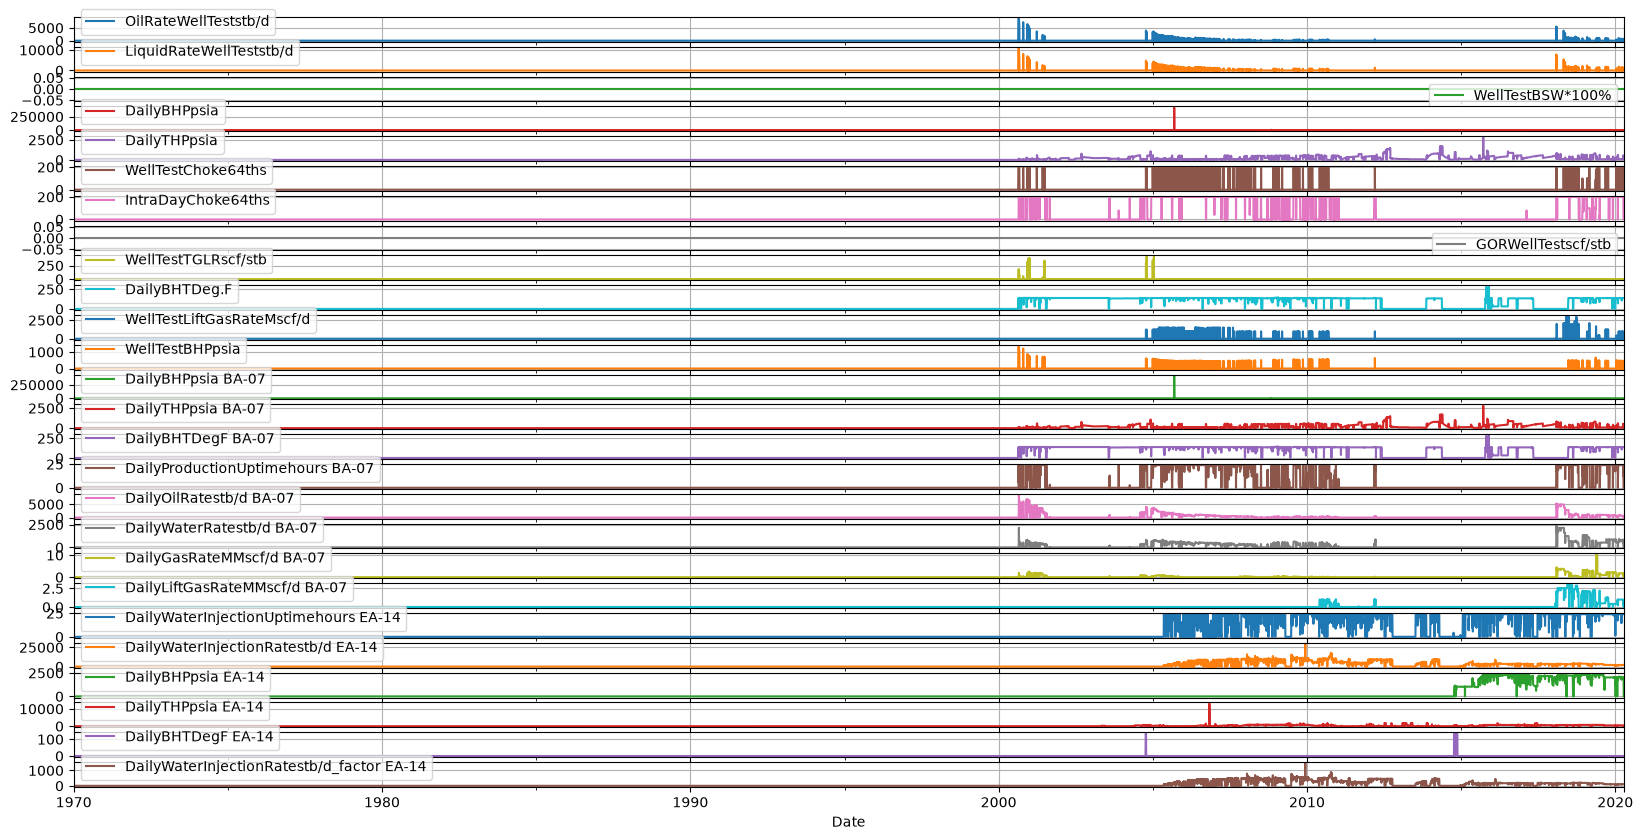

In [10]:
df.plot(subplots=True, grid=True, figsize=(20,10))

array([<Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>], dtype=object)

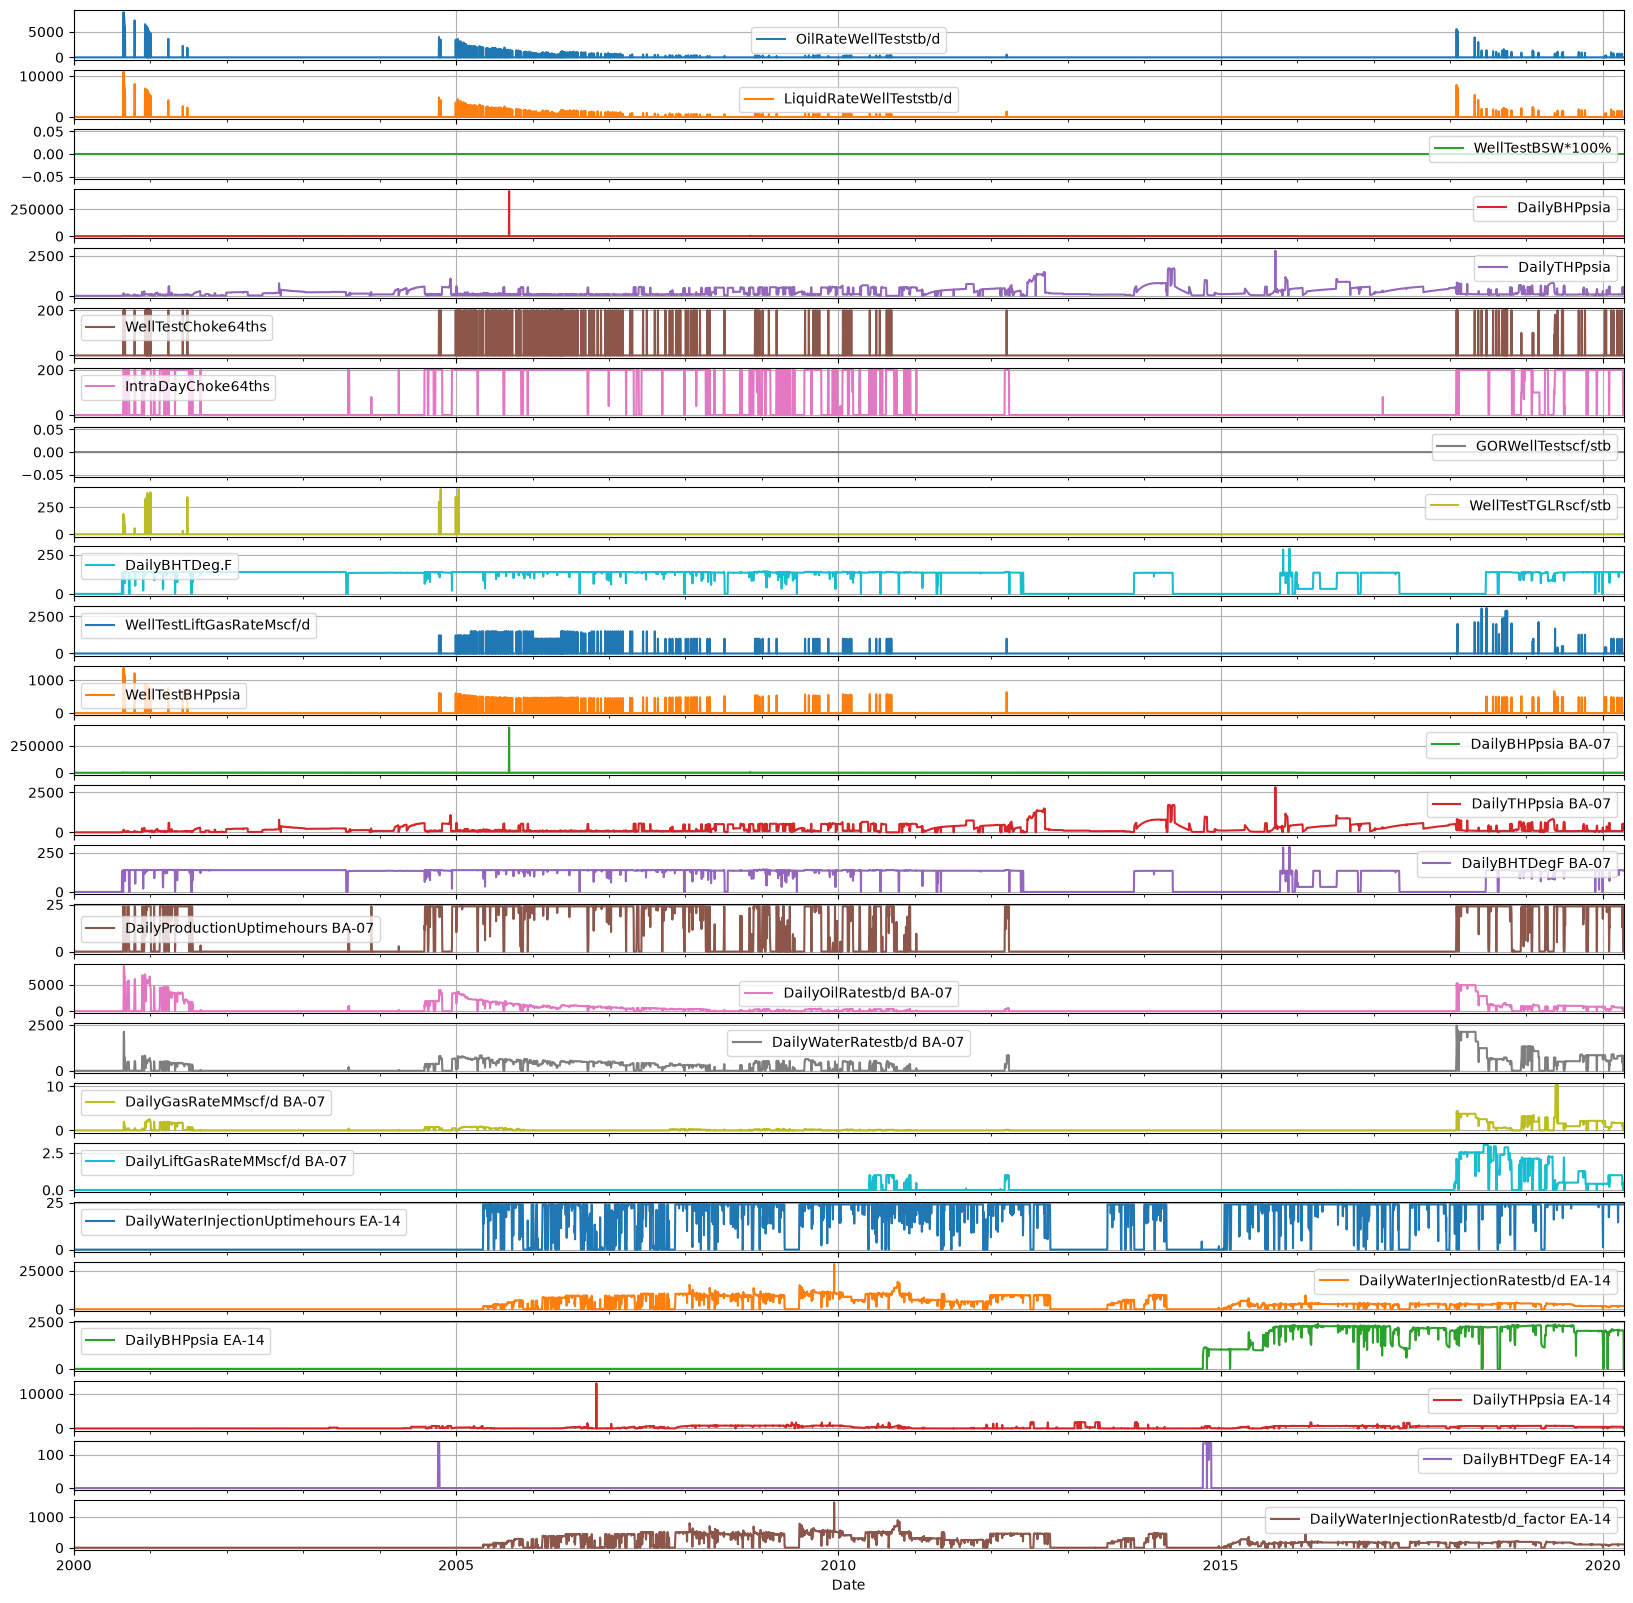

In [ ]:
df_cropped = df[df.index >= '2000-01-01']
df_cropped.plot(subplots=True, grid=True, figsize=(20,10))

DailyWaterRatestb/d BA-07                    0.774489
DailyProductionUptimehours BA-07             0.648528
IntraDayChoke64ths                           0.629596
DailyGasRateMMscf/d BA-07                    0.614518
DailyLiftGasRateMMscf/d BA-07                0.410904
OilRateWellTeststb/d                         0.314401
LiquidRateWellTeststb/d                      0.304601
DailyTHPpsia BA-07                          -0.256149
DailyTHPpsia                                -0.256149
WellTestBHPpsia                              0.230353
WellTestTGLRscf/stb                          0.221464
WellTestChoke64ths                           0.193097
WellTestLiftGasRateMscf/d                    0.121853
DailyWaterInjectionRatestb/d EA-14          -0.115625
DailyWaterInjectionRatestb/d_factor EA-14   -0.115625
DailyBHTDegF BA-07                           0.093378
DailyBHTDeg.F                                0.093378
DailyBHPpsia EA-14                           0.079866
DailyWaterInjectionUptimehou

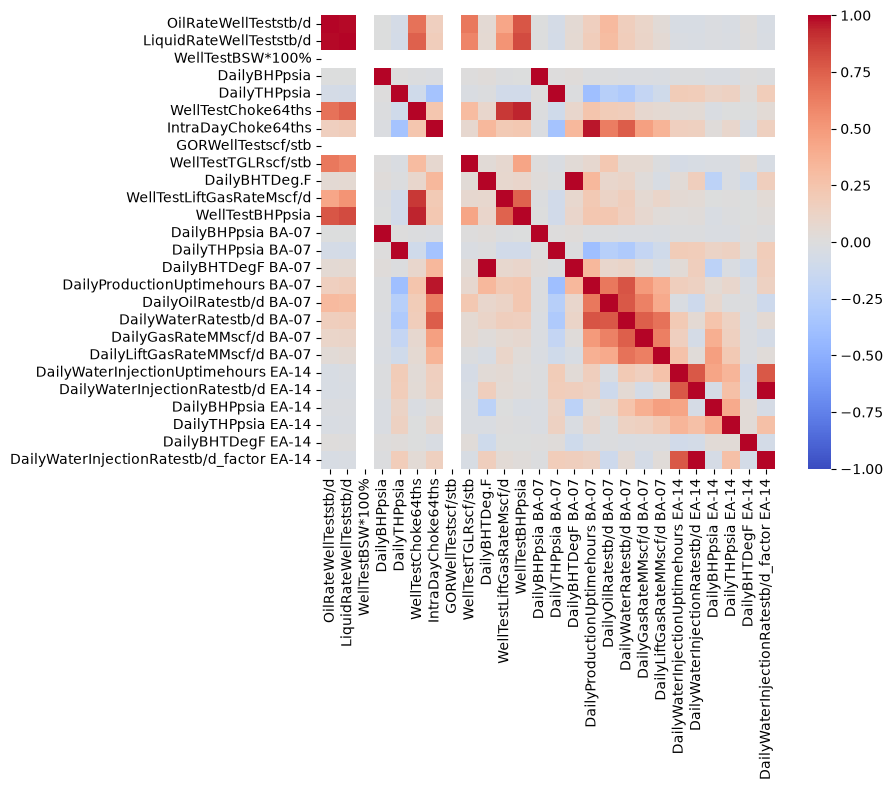

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

corr = df_cropped.corr(numeric_only=True)

print(corr[target].drop(target).sort_values(key=abs, ascending=False))

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=len(corr) <= 15, fmt=".2f", square=True)
plt.tight_layout()
plt.show()

In [13]:
important_cols = ['DailyWaterRatestb/d BA-07',
                  'DailyProductionUptimehours BA-07',
                  'WellTestLiftGasRateMscf/d',
                  'WellTestChoke64ths',
                  'IntraDayChoke64ths',
                  'DailyTHPpsia BA-07',
                  'DailyBHPpsia EA-14',
                  'DailyTHPpsia EA-14',
                  'DailyWaterInjectionRatestb/d_factor EA-14']

df1 = df_cropped[important_cols + [target]].copy()

array([<Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>, <Axes: xlabel='Date'>], dtype=object)

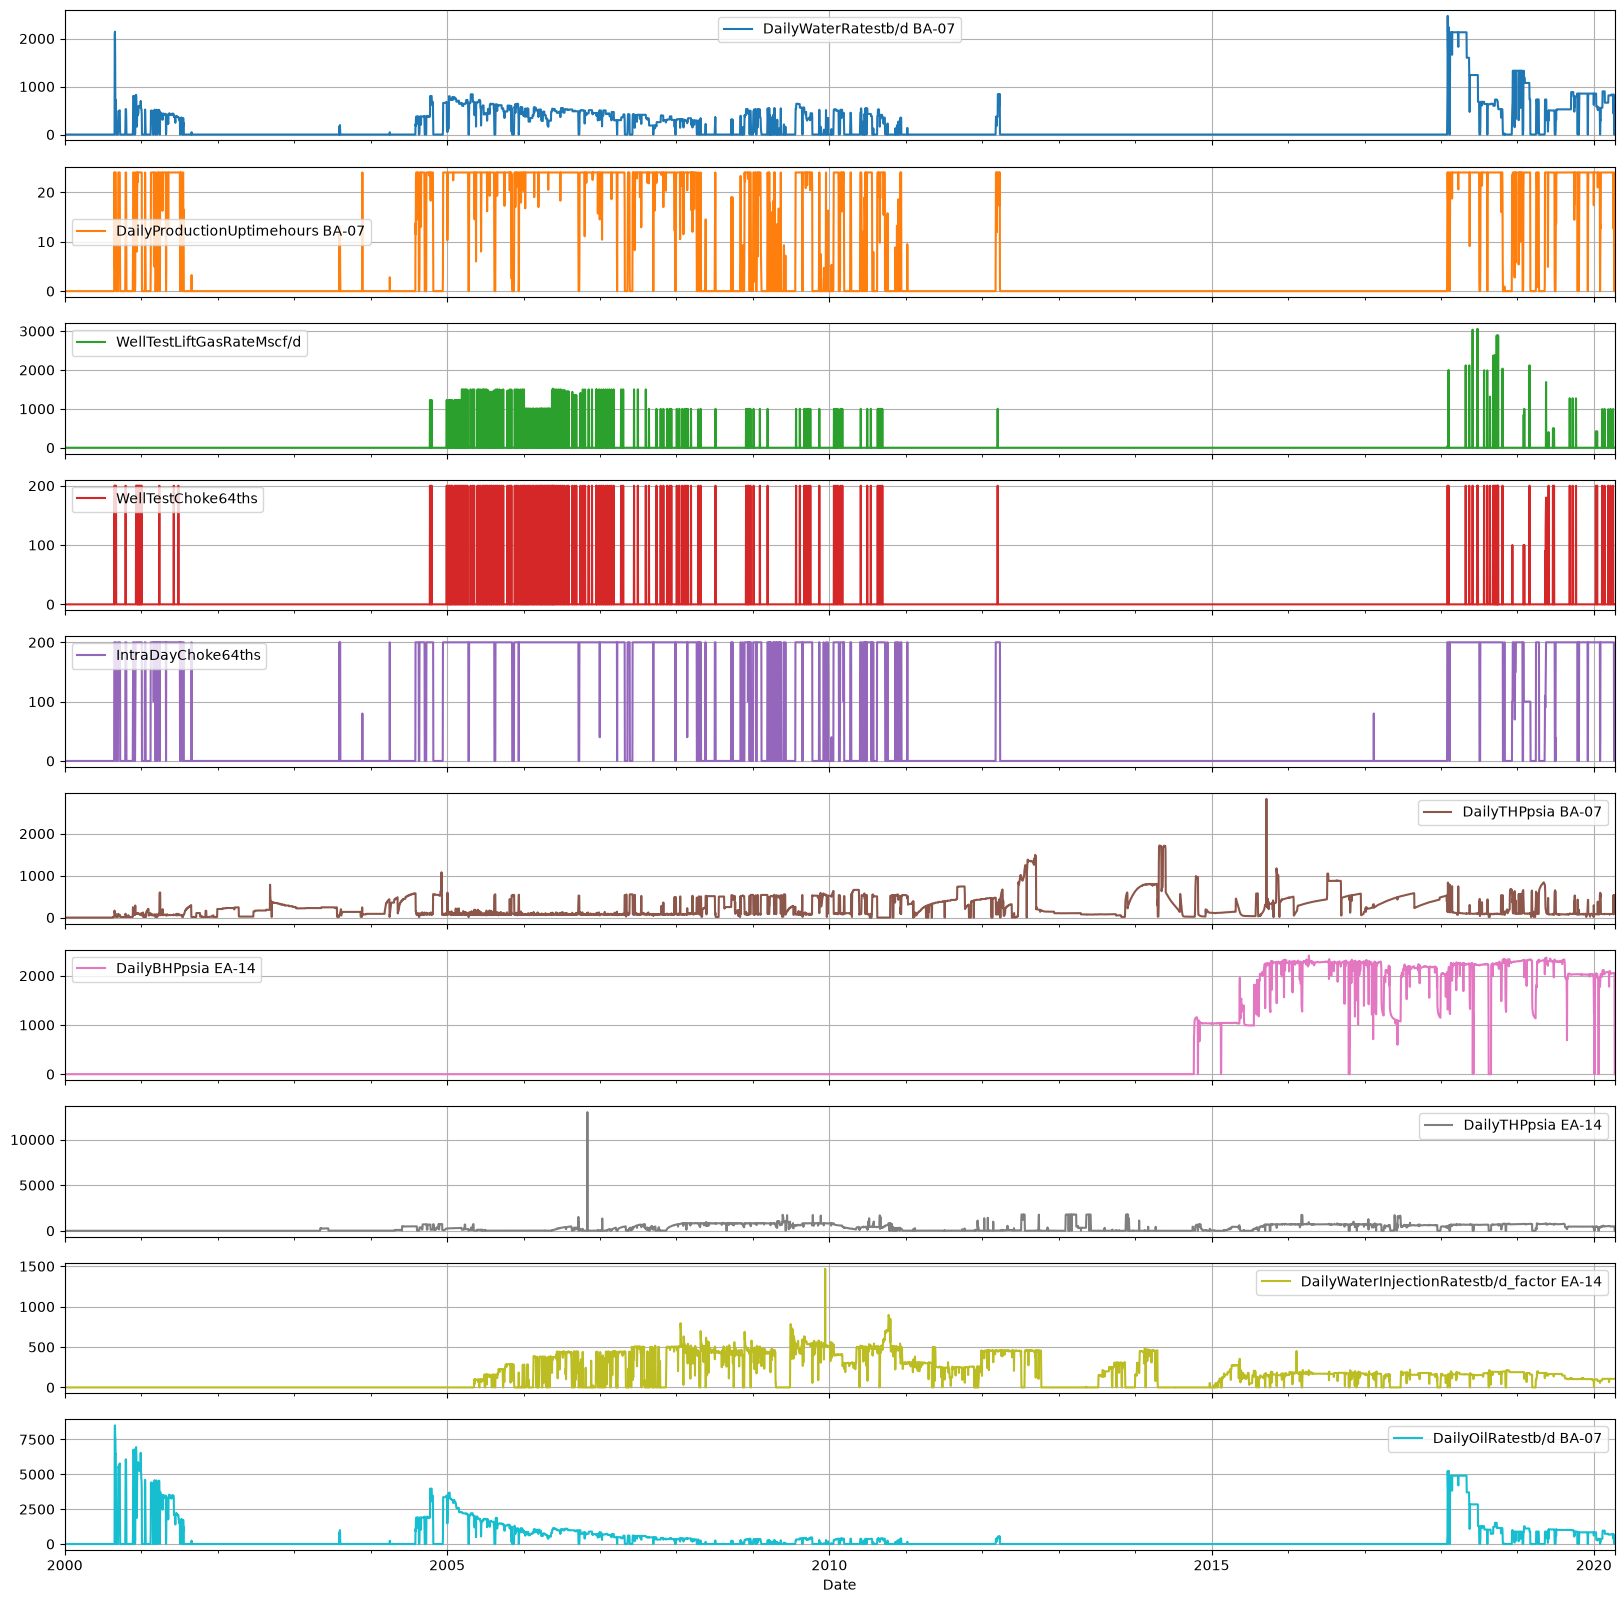

In [ ]:
df1.plot(subplots=True, grid=True, figsize=(20, 10))

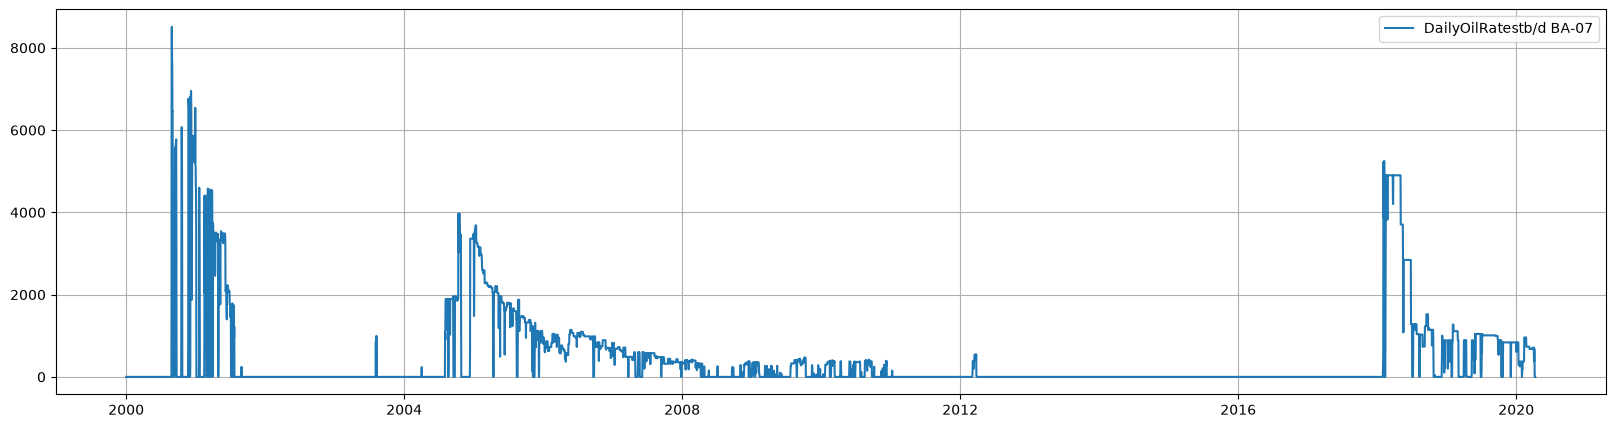

In [15]:
plt.figure(figsize=(20, 5))
plt.plot(df1.index, df1[target], label=target)
plt.grid()
plt.legend()
plt.show()

# Preparing data

In [16]:
window = 30
horizon = 1
batch_size = 32

In [17]:
from sklearn.preprocessing import StandardScaler

n = len(df1)
i_tr, i_va = int(n * 0.35), int(n * 0.65)

scaler = StandardScaler().fit(df1.iloc[:i_tr])
df1_scaled = pd.DataFrame(scaler.transform(df1), columns=df1.columns, index=df1.index)

target_idx = df1_scaled.columns.get_loc(target)

data = df1_scaled.to_numpy('float32')
targets = df1_scaled[target].to_numpy('float32')

def make_ds(label_start, label_end, shuffle=False):
    starts = np.arange(label_start - window, label_end - window - horizon + 1)

    xs = np.stack([data[i:i + window] for i in starts])

    ys = np.stack([
        targets[i + window:i + window + horizon]
        for i in starts
    ])

    ds = tf.data.Dataset.from_tensor_slices((xs, ys))

    if shuffle:
        ds = ds.shuffle(len(xs))

    return ds.batch(batch_size)

train_ds = make_ds(window, i_tr, shuffle=True)
train_eval_ds = make_ds(window, i_tr, shuffle=False)
val_ds   = make_ds(i_tr, i_va)
test_ds  = make_ds(i_va, n)

dates = df1.index
d_tr = dates[window: i_tr - horizon + 1]
d_va = dates[i_tr  : i_va - horizon + 1]
d_te = dates[i_va  : n    - horizon + 1]

for x,y in train_ds.take(1): print(x.shape); print(y.shape)

(32, 30, 10)
(32, 1)


E0000 00:00:1790782588.531420  101218 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [18]:
print("Train target:")
print(df1[target].iloc[:i_tr].describe())

print("\nValidation target:")
print(df1[target].iloc[i_tr:i_va].describe())

print("\nTest target:")
print(df1[target].iloc[i_va:].describe())

Train target:
count    2592.000000
mean      747.792207
std      1250.232241
min         0.000000
25%         0.000000
50%         0.000000
75%      1037.505000
max      8509.960000
Name: DailyOilRatestb/d BA-07, dtype: float64

Validation target:
count    2221.000000
mean      132.433224
std       197.638619
min         0.000000
25%         0.000000
50%         0.000000
75%       326.070000
max       723.640000
Name: DailyOilRatestb/d BA-07, dtype: float64

Test target:
count    2593.000000
mean      408.543533
std       998.825179
min         0.000000
25%         0.000000
50%         0.000000
75%       357.190000
max      5247.370000
Name: DailyOilRatestb/d BA-07, dtype: float64


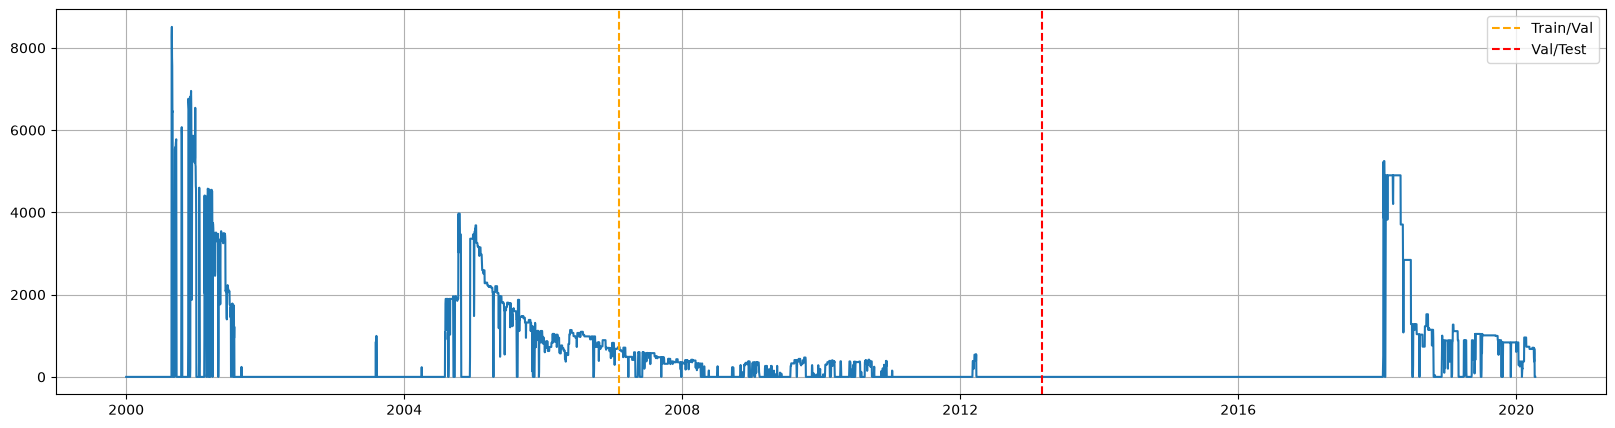

In [19]:
plt.figure(figsize=(20, 5))
plt.plot(df1.index, df1[target])
plt.axvline(df1.index[i_tr], linestyle='--', color='orange', label='Train/Val')
plt.axvline(df1.index[i_va], linestyle='--', color='red', label='Val/Test')
plt.grid()
plt.legend()
plt.show()

# Models

In [20]:
import time
from tensorflow.keras.layers import Dense,LSTM,Dropout,Input,GRU,LayerNormalization
from tensorflow.keras.regularizers import l2

tf.keras.backend.clear_session()
tf.random.set_seed(42)

def build_lstm_model(window, n_features, horizon, units=50, dropout=0.2, lr=1e-3, l2_r=1e-4):
    inputs = Input(shape=(window, n_features))
    x = LSTM(units, 
             return_sequences=True, 
             dropout=dropout,
             kernel_regularizer=l2(l2_r),
             recurrent_regularizer=l2(l2_r)
             )(inputs)
    x = LayerNormalization()(x)

    x = LSTM(units // 2,
             return_sequences=False,
             dropout = dropout,
             kernel_regularizer=l2(l2_r)
             )(x)

    x = Dense(units, activation='relu', kernel_regularizer=l2(l2_r))(x)
    x = Dropout(dropout)(x)
    x = Dense(units // 2, activation='relu')(x)
    delta = Dense(horizon)(x)
    last_oil = inputs[:, -1, target_idx:target_idx+1]
    outputs = last_oil + delta

    model = tf.keras.Model(inputs, outputs, name="oil_rate_lstm")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr, clipnorm=1.0),
        loss=tf.keras.losses.Huber(),
        metrics=["mae"],
    )
    return model


def build_gru_model(window, n_features, horizon, units=50, dropout=0.2, lr=1e-3, l2_r=1e-4):
    inputs = Input(shape=(window, n_features))
    x = GRU(units, 
             return_sequences=True, 
             dropout=dropout,
             recurrent_dropout=0.1,
             kernel_regularizer=l2(l2_r),
             recurrent_regularizer=l2(l2_r)
             )(inputs)
    x = LayerNormalization()(x)

    x = GRU(units // 2,
             return_sequences=False,
             dropout = dropout,
             kernel_regularizer=l2(l2_r)
             )(x)

    x = Dense(units, activation='relu', kernel_regularizer=l2(l2_r))(x)
    x = Dropout(dropout)(x)
    x = Dense(units // 2, activation='relu')(x)
    delta = Dense(horizon)(x)
    last_oil = inputs[:, -1, target_idx:target_idx+1]
    outputs = last_oil + delta

    model = tf.keras.Model(inputs, outputs, name="oil_rate_gru")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr, clipnorm=1.0),
        loss=tf.keras.losses.Huber(),
        metrics=["mae"],
    )
    return model

In [21]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_mae', patience=24, verbose=1, min_delta=1e-4, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_mae', factor=0.5, patience=3),
]

## LSTM

In [22]:
x_batch, _ = next(iter(train_ds))
_, window, n_features = x_batch.shape

lstm_model = build_lstm_model(window, n_features, horizon=horizon)
lstm_model.summary()

Model: "oil_rate_lstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 30, 10)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 30, 50)    │     12,200 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 30, 50)    │        100 │ lstm[0][0]        │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 25)        │      7,600 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 50)        │      1,300 │ lstm_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 50)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 25)        │      1,275 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 1)         │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         26 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 1)         │          0 │ get_item[0][0],   │
│                     │                   │            │ dense_2[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 22,501 (87.89 KB)

 Trainable params: 22,501 (87.89 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
t0 = time.perf_counter()
history = lstm_model.fit(train_ds, validation_data=val_ds, epochs=100, callbacks=callbacks, shuffle=False)
train_time = time.perf_counter() - t0

results = lstm_model.evaluate(test_ds, return_dict=True)
print(results)
print(f"Training time: {train_time:.1f} s")

Epoch 1/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 0.0640 - mae: 0.1408 - val_loss: 0.0191 - val_mae: 0.0607 - learning_rate: 0.0010
Epoch 2/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0597 - mae: 0.1170 - val_loss: 0.0175 - val_mae: 0.0512 - learning_rate: 0.0010
Epoch 3/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0578 - mae: 0.1058 - val_loss: 0.0165 - val_mae: 0.0542 - learning_rate: 0.0010
Epoch 4/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0566 - mae: 0.1045 - val_loss: 0.0154 - val_mae: 0.0501 - learning_rate: 0.0010
Epoch 5/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0550 - mae: 0.1024 - val_loss: 0.0146 - val_mae: 0.0469 - learning_rate: 0.0010
Epoch 6/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0544 - mae: 0.1015 - val_loss: 0.0141 - val_mae: 0.0610 - learning_rate: 0.0010
Epoch 7/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0538 - mae: 0.0974 - val_loss: 0.0121 - val_mae: 0.0414 - learning_rate: 0.0010
Epoch 

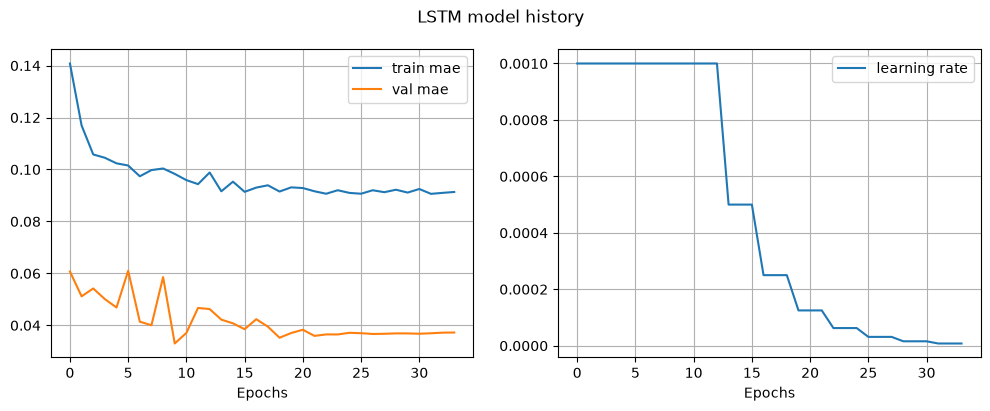

In [24]:
maes = lstm_model.history.history['mae']
val_maes = lstm_model.history.history['val_mae']
lrs = lstm_model.history.history['learning_rate']

fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(12, 4))

axs[0].plot(range(len(maes)),maes,label='train mae')
axs[0].plot(range(len(val_maes)),val_maes,label='val mae')
axs[0].set_xlabel("Epochs")
axs[0].legend()
axs[0].grid()
axs[1].plot(range(len(lrs)),lrs,label='learning rate')
axs[1].set_xlabel("Epochs")
axs[1].legend()
axs[1].grid()

fig.suptitle("LSTM model history")
plt.show()

In [25]:
mean = scaler.mean_[target_idx]
std  = scaler.scale_[target_idx]

y_pred = lstm_model.predict(test_ds, verbose=0)[:, 0]
y_true = np.concatenate([y.numpy()[:, 0] for _, y in test_ds])

y_pred_real = y_pred * std + mean
y_true_real = y_true * std + mean

prod = y_true_real > 5
for name, mask in [("producing", prod), ("shut-in", ~prod)]:
    e = y_pred_real[mask] - y_true_real[mask]
    print(f"{name:10s} n={mask.sum():5d}  MAE={np.abs(e).mean():.1f}")

yt, yp = y_true_real[1:], y_true_real[:-1]
m = yt > 5
print("naive producing MAE:", np.abs(yp[m] - yt[m]).mean())
print("naive shut-in MAE:  ", np.abs(yp[~m] - yt[~m]).mean())

producing  n=  681  MAE=123.7
shut-in    n= 1912  MAE=39.2
naive producing MAE: 89.32481737520499
naive shut-in MAE:   5.025075848494213


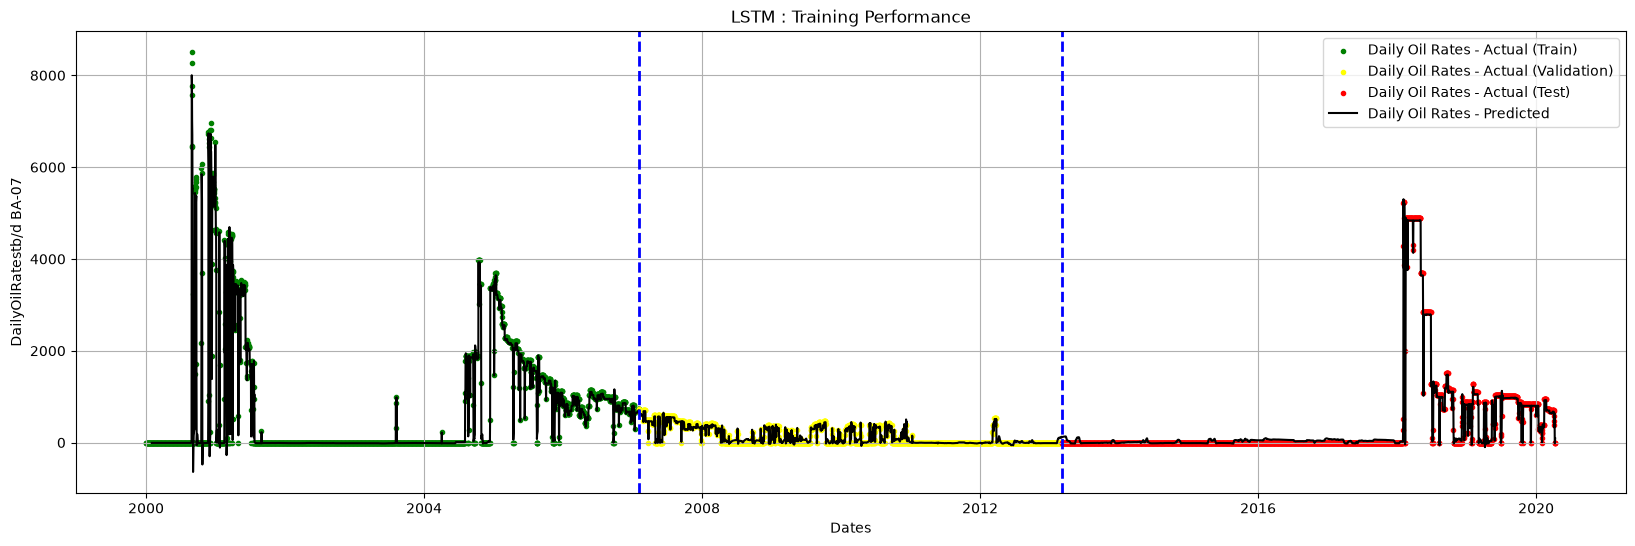

In [26]:
mean = scaler.mean_[target_idx]
std  = scaler.scale_[target_idx]

y_train  = np.concatenate([y.numpy() for _, y in train_eval_ds])
y_train  = y_train * std + mean
yp_train = lstm_model.predict(train_eval_ds, verbose=0)
yp_train = yp_train * std + mean

y_val  = np.concatenate([y.numpy() for _, y in val_ds])
y_val  = y_val * std + mean
yp_val = lstm_model.predict(val_ds, verbose=0)
yp_val = yp_val * std + mean

y_test  = np.concatenate([y.numpy() for _, y in test_ds])
y_test  = y_test * std + mean
yp_test = lstm_model.predict(test_ds, verbose=0)
yp_test = yp_test * std + mean

plt.figure(figsize=(20,6))

plt.scatter(dates[:i_tr],targets[:i_tr] * std + mean,marker='.',color='green',label='Daily Oil Rates - Actual (Train)')
plt.scatter(dates[i_tr:i_va],targets[i_tr:i_va] * std + mean,marker='.',color='yellow',label='Daily Oil Rates - Actual (Validation)')
plt.scatter(dates[i_va:n], targets[i_va:n] * std + mean, marker='.', color='red', label='Daily Oil Rates - Actual (Test)')

plt.plot(d_tr,yp_train[:, 0],label='Daily Oil Rates - Predicted',color='black')
plt.plot(d_va,yp_val[:, 0],color='black')
plt.plot(d_te,yp_test[:, 0],color='black')

plt.axvline(x=dates[i_tr], color='blue', lw=2, ls='--')
plt.axvline(x=dates[i_va], color='blue', lw=2, ls='--')

plt.title('LSTM : Training Performance')
plt.xlabel('Dates')
plt.ylabel(target)

plt.grid()
plt.legend()
plt.show()

## GRU

In [27]:
x_batch, _ = next(iter(train_ds))
_, window, n_features = x_batch.shape

gru_model = build_gru_model(window, n_features, horizon=horizon)
gru_model.summary()

Model: "oil_rate_gru"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 30, 10)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 30, 50)    │      9,300 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 50)    │        100 │ gru[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_1 (GRU)         │ (None, 25)        │      5,775 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 50)        │      1,300 │ gru_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 50)        │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 25)        │      1,275 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 1)         │          0 │ input_layer_1[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 1)         │         26 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 1)         │          0 │ get_item_1[0][0], │
│                     │                   │            │ dense_5[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 17,776 (69.44 KB)

 Trainable params: 17,776 (69.44 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
t0 = time.perf_counter()
history = gru_model.fit(train_ds, validation_data=val_ds,
                    epochs=100, callbacks=callbacks, shuffle=False)
train_time = time.perf_counter() - t0

results = gru_model.evaluate(test_ds, return_dict=True)
print(results)
print(f"Training time: {train_time:.1f} s")

Epoch 1/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 0.0759 - mae: 0.1882 - val_loss: 0.0208 - val_mae: 0.0834 - learning_rate: 0.0010
Epoch 2/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0603 - mae: 0.1284 - val_loss: 0.0175 - val_mae: 0.0676 - learning_rate: 0.0010
Epoch 3/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0575 - mae: 0.1140 - val_loss: 0.0145 - val_mae: 0.0415 - learning_rate: 0.0010
Epoch 4/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0559 - mae: 0.1094 - val_loss: 0.0135 - val_mae: 0.0450 - learning_rate: 0.0010
Epoch 5/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0545 - mae: 0.1059 - val_loss: 0.0123 - val_mae: 0.0384 - learning_rate: 0.0010
Epoch 6/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0533 - mae: 0.1022 - val_loss: 0.0115 - val_mae: 0.0402 - learning_rate: 0.0010
Epoch 7/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0522 - mae: 0.1016 - val_loss: 0.0108 - val_mae: 0.0373 - learning_rate: 0.0010
Epoch 

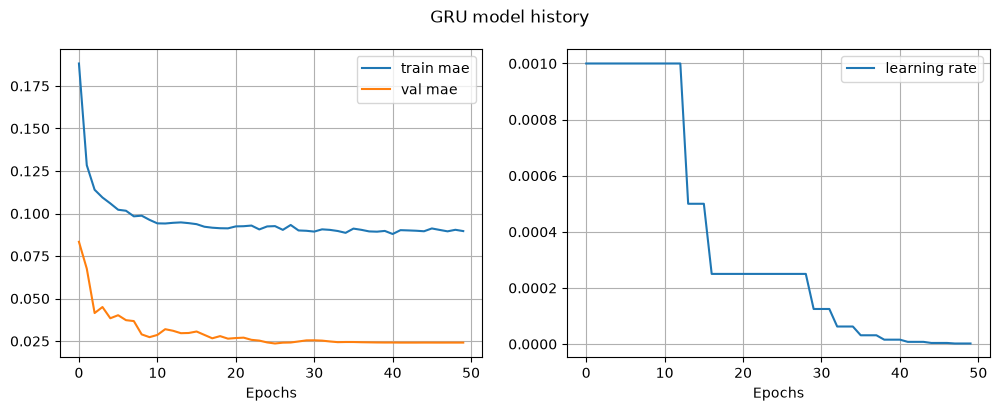

In [29]:
maes = gru_model.history.history['mae']
val_maes = gru_model.history.history['val_mae']
lrs = gru_model.history.history['learning_rate']

fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(12, 4))

axs[0].plot(range(len(maes)),maes,label='train mae')
axs[0].plot(range(len(val_maes)),val_maes,label='val mae')
axs[0].set_xlabel("Epochs")
axs[0].legend()
axs[0].grid()
axs[1].plot(range(len(lrs)),lrs,label='learning rate')
axs[1].set_xlabel("Epochs")
axs[1].legend()
axs[1].grid()

fig.suptitle("GRU model history")
plt.show()

In [30]:
mean = scaler.mean_[target_idx]
std  = scaler.scale_[target_idx]

y_pred = gru_model.predict(test_ds, verbose=0)[:, 0]
y_true = np.concatenate([y.numpy()[:, 0] for _, y in test_ds])

y_pred_real = y_pred * std + mean
y_true_real = y_true * std + mean

prod = y_true_real > 5
for name, mask in [("producing", prod), ("shut-in", ~prod)]:
    e = y_pred_real[mask] - y_true_real[mask]
    print(f"{name:10s} n={mask.sum():5d}  MAE={np.abs(e).mean():.1f}")

yt, yp = y_true_real[1:], y_true_real[:-1]
m = yt > 5
print("naive producing MAE:", np.abs(yp[m] - yt[m]).mean())
print("naive shut-in MAE:  ", np.abs(yp[~m] - yt[~m]).mean())

producing  n=  681  MAE=104.7
shut-in    n= 1912  MAE=16.7
naive producing MAE: 89.32481737520499
naive shut-in MAE:   5.025075848494213


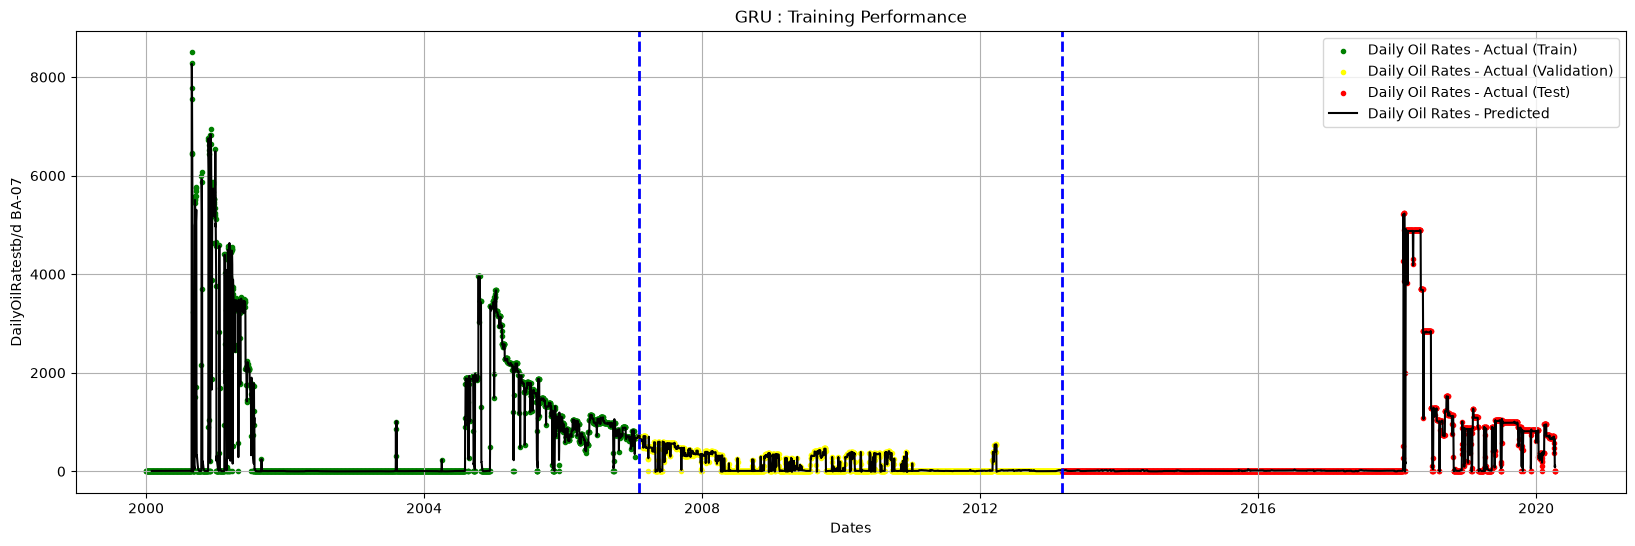

In [31]:
mean = scaler.mean_[target_idx]
std  = scaler.scale_[target_idx]

y_train  = np.concatenate([y.numpy() for _, y in train_eval_ds])
y_train  = y_train * std + mean
yp_train = gru_model.predict(train_eval_ds, verbose=0)
yp_train = yp_train * std + mean

y_val  = np.concatenate([y.numpy() for _, y in val_ds])
y_val  = y_val * std + mean
yp_val = gru_model.predict(val_ds, verbose=0)
yp_val = yp_val * std + mean

y_test  = np.concatenate([y.numpy() for _, y in test_ds])
y_test  = y_test * std + mean
yp_test = gru_model.predict(test_ds, verbose=0)
yp_test = yp_test * std + mean

plt.figure(figsize=(20,6))

plt.scatter(dates[:i_tr],targets[:i_tr] * std + mean,marker='.',color='green',label='Daily Oil Rates - Actual (Train)')
plt.scatter(dates[i_tr:i_va],targets[i_tr:i_va] * std + mean,marker='.',color='yellow',label='Daily Oil Rates - Actual (Validation)')
plt.scatter(dates[i_va:n], targets[i_va:n] * std + mean, marker='.', color='red', label='Daily Oil Rates - Actual (Test)')

plt.plot(d_tr,yp_train[:, 0],label='Daily Oil Rates - Predicted',color='black')
plt.plot(d_va,yp_val[:, 0],color='black')
plt.plot(d_te,yp_test[:, 0],color='black')

plt.axvline(x=dates[i_tr], color='blue', lw=2, ls='--')
plt.axvline(x=dates[i_va], color='blue', lw=2, ls='--')

plt.title('GRU : Training Performance')
plt.xlabel('Dates')
plt.ylabel(target)

plt.grid()
plt.legend()
plt.show()